In [1]:
from pycalphad import Workspace, Database, variables as v
from pycalphad.property_framework import IsolatedPhase, ModelComputedProperty
import matplotlib.pyplot as plt
import numpy as np

## Duplicated 2026-10-28 to test TDB provenance

This is a duplicate of `stability_analysis_nonisotropic.ipynb`, created to test whether the `coherent_Hessian` sign reported in manuscript Figure 4(a) at 500 C / 773.15 K for equiatomic Hf25Nb25Ti25V25 depends on which TDB is used.

**Change from the original notebook:** every `Database('HfNbVTi.tdb')` call has been replaced with the production TDB actually used for the Fig. 7(b) quaternary phase-field simulation, `data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb`. `HfNbVTi.tdb` does not exist anywhere in this repository and could not be independently verified.

**Unchanged (still from the original, untraceable source):** the eigenstrain vector `eta`, the isotropic modulus `M`, and `lattice_param` in each composition's cell are left exactly as in the original notebook (hand-transcribed from a now-missing `sqs_elastic_constants_HfNbVTi.csv`, per the original author's comment "can be pulled from excel sheet"). Only the chemical Hessian's source database is changed, to isolate that one variable.

In [2]:
# Coherent Spinodal 
# This is my modified bond model function that also calculates the derivatives; it requires the dependent component to be specified
import pandas as pd

def add_lattice_parameter_BCC(dataset: pd.DataFrame, elements: list[str], dependent_component) -> pd.DataFrame:
    '''https://github.com/tandocca/Lattice-Parameter/blob/main/README.md'''
    from itertools import product
    from math import sqrt
    
    B2_bond_lengths = { 
    "HfHf": 3.0673656116191044,
    "HfNb": 2.9572441802697935,
    "HfTi": 2.9445255192919726,
    "HfV":  2.844887616911763,
    "NbHf": 2.9572441802697935,
    "NbNb": 2.861885570144507,
    "NbTi": 2.8249641822131335,
    "NbV":  2.737275009925361,
    "TiHf": 2.9445255192919726,
    "TiNb": 2.8249641822131335,
    "TiTi": 2.810474121277211,
    "TiV":  2.6985800750769795,
    "VHf":  2.844887616911763,
    "VNb":  2.737275009925361,
    "VTi":  2.6985800750769795,
    "VV":   2.591424330622251,
    }
    
    lp_values = []
    
    independent_elements = [x for x in elements if x != dependent_component]
    
    lp_grad = {key: [] for key in independent_elements}
    

    for _, row in dataset.iterrows():
        avg_bond = 0.0
        fractions = row[elements].to_dict()

        for e1, e2 in product(elements, repeat=2):
            pair_key = "".join([e1,e2])
            if pair_key not in B2_bond_lengths:
                # optionally handle missing keys (skip or raise)
                continue
            c_pair = fractions[e1] * fractions[e2]
            avg_bond += B2_bond_lengths[pair_key] * c_pair
        
        for key in lp_grad:
            derivative = 0
            for e1, e2 in product(independent_elements, [key]):
                pair_key = "".join([e1,e2])
                if pair_key not in B2_bond_lengths:
                    # optionally handle missing keys (skip or raise)
                    continue
                # 2/sqrt(3)*(2*x_i*d_ik)
                derivative += 4*fractions[e1]*B2_bond_lengths[pair_key]/sqrt(3)
                
            el_list = [x for x in independent_elements if x != key]
                
            for e1, e2 in product(el_list, [dependent_component]):
                derivative += -4*fractions[e1]*B2_bond_lengths[pair_key]/sqrt(3)
            
            derivative += 4*(fractions[dependent_component]-fractions[key])*B2_bond_lengths["".join([dependent_component,key])]/sqrt(3)
            derivative += -4*fractions[dependent_component]*B2_bond_lengths["".join([dependent_component,dependent_component])]/sqrt(3)
            
            lp_grad[key].append(derivative)

        # Compute lattice parameter for BCC structure: a = 2*d111/sqrt(3)
        lp = round((2 / sqrt(3)) * avg_bond,4)
        lp_values.append(lp)

    dataset['pred_a_bcc_DFT_(A)'] = lp_values
    for key in lp_grad:
        dataset['da/dx_'+key] = lp_grad[key]
    
    return dataset

def change_directory_to_current_py_file():
    try:
        import os
        os.chdir(os.path.split(os.path.abspath(__file__))[0])
    except Exception as e:
        print(f'\nDirectory change or os module error:\n\n{e}')

change_directory_to_current_py_file()

def import_data(file_name: str) -> pd.DataFrame:
    import os
    csv_file = f"{file_name}.csv"
    if os.path.exists(csv_file):
        data = pd.read_csv(csv_file)
        return data
    
    with pd.ExcelFile(f"{file_name}.xlsx") as xlsx:
        sheet_names = xlsx.sheet_names
        data = pd.read_excel(xlsx, sheet_name=sheet_names[0])
    data = data.filter(regex='^(?!Unnamed|Index)')
    # data.to_csv(csv_file, index=False)  # Save as CSV for future use
    return data

def extract_elements(data: pd.DataFrame) -> list[str]:
    elements = [col for col in data.columns if len(col) <= 2]
    return elements

file_name = 'sqs_elastic_constants_HfNbVTi'
dataset: pd.DataFrame = import_data(f'{file_name}')
elements = ['Hf', 'Nb', 'Ti', 'V']
dependent_component = 'V'
# elements = extract_elements(dataset) # alternatively
dataset: pd.DataFrame = add_lattice_parameter_BCC(dataset, elements,dependent_component)

dataset


Directory change or os module error:

name '__file__' is not defined


FileNotFoundError: [Errno 2] No such file or directory: 'sqs_elastic_constants_HfNbVTi.xlsx'

In [3]:
# Each composition from the dataset is set as conditions for the equilibrium calculation. First derivatives of the chemical potential of each component
# are calculated with respect to the three independent composition variables. The second derivatives of the Gibbs energy with respect to the independent
# composition variables are then calculated using the relation dG/dxA = muA - muB where B is the dependent component. 
# Thus, d^2G/dxAdxA = dmuA/dxA - dmuB/dxA. The Hessian is built from its individual components, and some fancy linear algebra is done to transform from 
# a simplex space to a cartesian space so that we do the eigenanalysis in space where the eigenvectors are actually orthogonal. The "O" matrix comes from
# Table 1 in Kadirvel et al., Scripta Materialia. (2022). 
import pandas as pd

eigenvalue_1 = []
eigenvalue_2 = []
eigenvalue_3 = []

eigenvalue_1_chem = []
eigenvalue_2_chem = []
eigenvalue_3_chem = []

drop_list = []
T = 600
# changed column titles to have the second letter lowercase here as well
for row, cols in dataset.iterrows():
    print(row)
    wks = Workspace(database=Database('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): dataset.loc[row, 'Hf'],v.X('NB'): dataset.loc[row, 'Nb'], v.X('TI'): dataset.loc[row, 'Ti'], v.T: T, v.P: 101325})

    try:
        dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
        dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
        dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
        dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

        dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
        dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
        dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
        dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

        dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
        dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
        dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
        dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

        d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
        d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
        d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

        d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
        d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
        d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

        d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
        d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
        d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI
        #this is now the chemical Hessian
        chem_Hessian = np.array([[d2G_dxHFdxHF, d2G_dxHFdxNB, d2G_dxHFdxTI], [d2G_dxNBdxHF, d2G_dxNBdxNB, d2G_dxNBdxTI], [d2G_dxTIdxHF, d2G_dxTIdxNB, d2G_dxTIdxTI]])
        #this is the eta vector 1/a*da/dx
        eta = np.array([[1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Hf'],1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Nb'],1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Ti']]])
        c11 = dataset.loc[row,'C11_GPa']*1e9
        c12 = dataset.loc[row,'C12_GPa']*1e9
        c44 = dataset.loc[row,'C44_GPa']*1e9
        lattice_param = dataset.loc[row, 'pred_a_bcc_DFT_(A)']
        #V=a^3*N_A/2
        V = (lattice_param*1e-10)**3*6.022e23/2
        #coherent contribution
        if 2*c44 - c11 + c12 > 0:
            Y = (c11+2*c12)*(c11-c12)/c11
        elif 2*c44 - c11 + c12 < 0:
            Y = 6*(c11+2*c12)*c44/(4*c44+c11+2*c12)
        coherent_Hessian = 2*Y*V*(eta.reshape(-1,1)@eta)
        #new total Hessian
        Hessian = chem_Hessian + coherent_Hessian
        O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
        orthogonal_coherent_Hessian = O.T@Hessian@O
        orthogonal_chem_Hessian = O.T@chem_Hessian@O

        values, vectors = np.linalg.eig(orthogonal_coherent_Hessian)
        sorted = np.sort(values)
        eigenvalue_1.append(sorted[0])
        eigenvalue_2.append(sorted[1])
        eigenvalue_3.append(sorted[2])

        values, vectors = np.linalg.eig(orthogonal_chem_Hessian)
        sorted = np.sort(values)
        eigenvalue_1_chem.append(sorted[0])
        eigenvalue_2_chem.append(sorted[1])
        eigenvalue_3_chem.append(sorted[2])

    except (ValueError, ZeroDivisionError) as e:
        drop_list.append(row)
        continue
        



NameError: name 'dataset' is not defined

In [4]:
# Here I am just adding a column in the dataframe that tells how many negative eigenvalues are present
eig_1_bin = [x > 0 for x in eigenvalue_1]
eig_2_bin = [x > 0 for x in eigenvalue_2]
eig_3_bin = [x > 0 for x in eigenvalue_3]

eig_sections = []
for i in range(len(eig_1_bin)):
    if eig_1_bin[i] and eig_2_bin[i] and eig_3_bin[i]:
        eig_sections.append(0)
    elif (not eig_1_bin[i]) and eig_2_bin[i] and eig_3_bin[i]:
        eig_sections.append(1)
    elif (not eig_1_bin[i]) and (not eig_2_bin[i]) and eig_3_bin[i]:
        eig_sections.append(2)
    else:
        eig_sections.append(3)

eig_1_bin_chem = [x > 0 for x in eigenvalue_1_chem]
eig_2_bin_chem = [x > 0 for x in eigenvalue_2_chem]
eig_3_bin_chem = [x > 0 for x in eigenvalue_3_chem]

eig_sections_chem = []
for i in range(len(eig_1_bin_chem)):
    if eig_1_bin_chem[i] and eig_2_bin_chem[i] and eig_3_bin_chem[i]:
        eig_sections_chem.append(0)
    elif (not eig_1_bin_chem[i]) and eig_2_bin_chem[i] and eig_3_bin_chem[i]:
        eig_sections_chem.append(1)
    elif (not eig_1_bin_chem[i]) and (not eig_2_bin_chem[i]) and eig_3_bin_chem[i]:
        eig_sections_chem.append(2)
    else:
        eig_sections_chem.append(3)

In [5]:
eig_dataset = pd.read_csv('sqs_elastic_constants_HfNbVTi.csv')
eig_dataset = eig_dataset.drop(drop_list)
eig_dataset['Eig_1']=eigenvalue_1
eig_dataset['Eig_2']=eigenvalue_2
eig_dataset['Eig_3']=eigenvalue_3
eig_dataset['Negative Eigenvalues']=eig_sections
eig_dataset['Eig_1_chem']=eigenvalue_1_chem
eig_dataset['Eig_2_chem']=eigenvalue_2_chem
eig_dataset['Eig_3_chem']=eigenvalue_3_chem
eig_dataset['Negative Eigenvalues_chem']=eig_sections_chem
eig_dataset

FileNotFoundError: [Errno 2] No such file or directory: 'sqs_elastic_constants_HfNbVTi.csv'

In [6]:
# Here is Brent's affine transformation code with n = 4. I commented out a lot that I didn't need
from matplotlib.patches import Polygon


def generate_regular_pentagon(radius=.5, center=(0, 0), rotation_angle=0):
    """
    Generate vertices of a regular pentagon and rotate it by a given angle.

    Parameters:
    - radius: The radius of the circumscribed circle.
    - center: The center of the pentagon.
    - rotation_angle: Rotation angle in radians.

    Returns:
    - vertices: List of vertices of the regular pentagon.
    """
    n = 4
    # Adjust the starting angle by π/5 to make one side flat on the horizontal
    angles = np.linspace(np.pi / 5, 2 * np.pi + np.pi / 5, n, endpoint=False)

    # Rotate the pentagon by the given rotation_angle
    angles += rotation_angle

    vertices = np.array([[center[0] + radius * np.cos(angle),
                          center[1] + radius * np.sin(angle)] for angle in angles])
    return vertices


def barycentric_to_cartesian(barycentric_coords, vertices):
    """
    Convert barycentric coordinates to Cartesian coordinates.

    Parameters:
    - barycentric_coords: Barycentric coordinates for each point.
    - vertices: Vertices of the polygon.

    Returns:
    - Cartesian coordinates of the points.
    """
    return np.dot(barycentric_coords, vertices)


def plot_pentagon_with_barycentric_projection(Q, barycentric_coords):
    """
    Plot the regular pentagon and barycentric coordinates.

    Parameters:
    - Q: List of vertices of the regular pentagon.
    - barycentric_coords: Barycentric coordinates of points.
    """
    #fig, ax = plt.subplots()

    # # Create the pentagon
    # polygon = Polygon(Q, closed=True, edgecolor='k', facecolor='lightgray')
    # ax.add_patch(polygon)
    #
    # # Plot the vertices
    # Q = np.array(Q)
    # ax.scatter(Q[:, 0], Q[:, 1], c='blue', label='Vertices')

    # Convert barycentric coordinates to Cartesian coordinates
    cartesian_coords = barycentric_to_cartesian(barycentric_coords, Q)

    return cartesian_coords


#for n in np.linspace(0,2,100):
n = .952
# Example usage
# Set a rotation angle (in radians). For example, np.pi/4 for 45 degrees
rotation_angle = np.pi / n  # 30 degrees

Q = generate_regular_pentagon(radius=1, center=(0, 0), rotation_angle=rotation_angle)



# comps2 has the new projected coords
elements = ['Hf','Nb','Ti','V']
comps2 = plot_pentagon_with_barycentric_projection(Q, eig_dataset[elements])

eig_dataset['proj0'] = comps2[:, 0]
eig_dataset['proj1'] = comps2[:, 1]

# Here I am breaking up the points into their discrete categories so they can be plotted separately (had to do this for the legend to work right)
comps_0_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==0]
comps_1_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==1]
comps_2_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==2]

# Plot the projections
plt.figure(figsize=(5,4))

plt.scatter(comps_0_neg_1500['proj0'],comps_0_neg_1500['proj1'],color='blue',label='Zero Negative Eigenvalues',s=81)
plt.scatter(comps_1_neg_1500['proj0'],comps_1_neg_1500['proj1'],color='green',label='One Negative Eigenvalue',s=49)
plt.scatter(comps_2_neg_1500['proj0'],comps_2_neg_1500['proj1'],color='red',label='Two Negative Eigenvalues',s=25)

plt.title('Coherent 600 K')
plt.axis('off')
plt.figtext(0.08,0.1, 'Hf')
plt.figtext(0.88,0.1, 'Nb')
plt.figtext(0.88,0.86, 'Ti')
plt.figtext(0.12,0.86, 'V')
plt.legend(bbox_to_anchor=(1,0.7))
#plt.savefig('coherent_600_inverse.pdf', bbox_inches = "tight")
#plt.savefig('coherent_1000_diff_sizes.pdf', bbox_inches = "tight")

NameError: name 'eig_dataset' is not defined

In [7]:
elements = ['Hf','Nb','Ti','V']
comps2 = plot_pentagon_with_barycentric_projection(Q, eig_dataset[elements])

eig_dataset['proj0'] = comps2[:, 0]
eig_dataset['proj1'] = comps2[:, 1]

# Here I am breaking up the points into their discrete categories so they can be plotted separately (had to do this for the legend to work right)
comps_0_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==0]
comps_1_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==1]
comps_2_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==2]

# Plot the projections
plt.figure(figsize=(5,4))

plt.scatter(comps_0_neg_1500['proj0'],comps_0_neg_1500['proj1'],color='blue',label='Zero Negative Eigenvalues',s=81)
plt.scatter(comps_1_neg_1500['proj0'],comps_1_neg_1500['proj1'],color='green',label='One Negative Eigenvalue',s=49)
plt.scatter(comps_2_neg_1500['proj0'],comps_2_neg_1500['proj1'],color='red',label='Two Negative Eigenvalues',s=25)


#plt.title('T = 600 K')
plt.title('Chemical 1000 K')
plt.axis('off')
plt.figtext(0.08,0.1, 'Hf')
plt.figtext(0.88,0.1, 'Nb')
plt.figtext(0.88,0.86, 'Ti')
plt.figtext(0.12,0.86, 'V')
plt.legend(bbox_to_anchor=(1,0.7))
#plt.savefig('chemical_1000_diff_sizes.pdf', bbox_inches = "tight")

NameError: name 'eig_dataset' is not defined

In [8]:
# Eigenvalue plots; all the same process, but at different compositions specified in the Workspace
# M, eta, and lattice parameter also have to be adjusted along with composition since they are functions of composition; can be pulled from excel sheet
wks = Workspace(database=Database('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.25,v.X('NB'): 0.25, v.X('TI'): 0.25, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.08620911, 0.07105138, 0.06485024]])

M = 149.323894513184*1e9
lattice_param = 3.2726
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

/opt/anaconda3/lib/python3.13/site-packages/pycalphad/io/tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


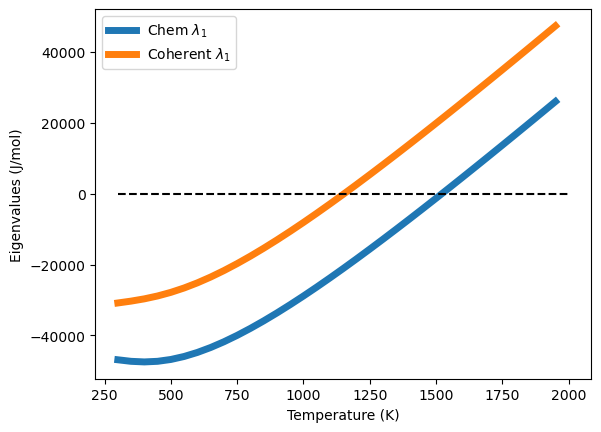

In [9]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
#plt.savefig('eigenvalues_Hf25.pdf', bbox_inches = "tight")

In [10]:
wks = Workspace(database=Database('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.1,v.X('NB'): 0.4, v.X('TI'): 0.4, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.03720351, 0.05484124, 0.05273471]])

M = 142.988156*1e9
lattice_param = 3.2702
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

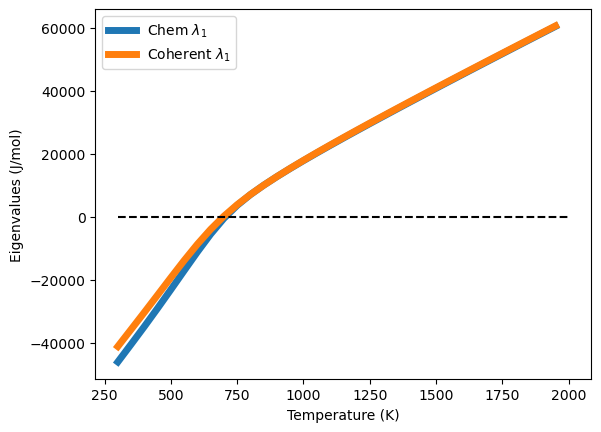

In [11]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
plt.savefig('eigenvalues_Hf1.pdf', bbox_inches = "tight")

In [12]:
wks = Workspace(database=Database('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.6,v.X('NB'): 0.1, v.X('TI'): 0.1, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.12660562, 0.08260484, 0.07816819]])

M = 161.764907*1e9
lattice_param = 3.3828
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

/opt/anaconda3/lib/python3.13/site-packages/pycalphad/io/tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


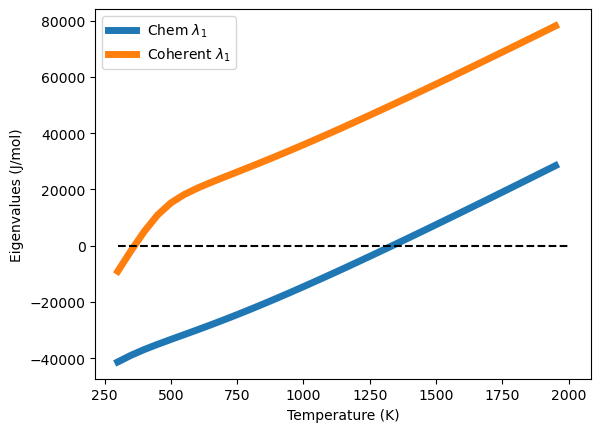

In [13]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
plt.savefig('eigenvalues_Hf4.pdf', bbox_inches = "tight")

ValueError: x and y must have same first dimension, but have shapes (9,) and (34,)

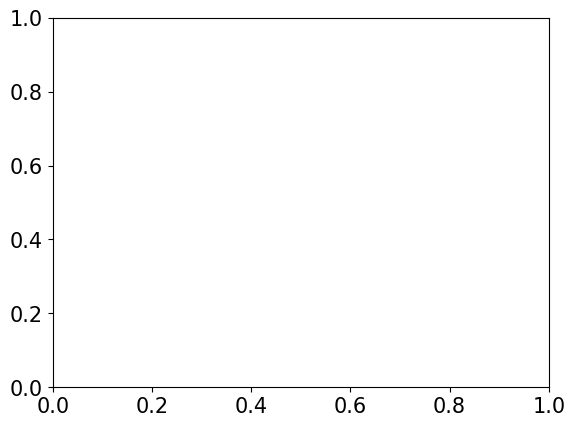

In [14]:
# Eigenvector plot for chemical Hessian at the same composition as the eigenvalue plot above
temps = np.arange(600,1050,50)

plt.rc('font',size=15)

plt.figure(1)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,0], label='Hf',linewidth=5)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,1], label='Nb',linewidth=5)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,2], label='Ti',linewidth=5)
plt.plot(temps, - np.array(chem_transformed_eigenvector1)[:,1] - np.array(chem_transformed_eigenvector1)[:,0] - np.array(chem_transformed_eigenvector1)[:,2], label='V',linewidth=5)
plt.plot([600,1000],[0,0],color='black',linestyle='dashed')
#plt.plot([1200,1200],[-1.25,1],color='red',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('First Eigenvector Components')
plt.legend(bbox_to_anchor=(1,0.7))
plt.savefig('eigenvector.pdf', bbox_inches = "tight")


## Added 2026-10-28 (second pass): recompute eta/M from the production SQS/ORB-MLIP CSV

The cells above only replaced the TDB; `eta`, `M`, and `lattice_param` were still the original notebook's hand-transcribed, untraceable values. This pass recomputes them properly from `data/HfNbTiV_BCC_PhaseForge_v2/sqs_elastic_constants_HfNbVTi-orb-v2.csv` (the same file `workflows/01b_lookup_elastic` uses for every other reported elastic calculation, including the Fig. 7(b) simulation's eigenstrain), using the same `phasefoundry.elasticity.sqs_interpolant` interpolation and the same central-finite-difference Vegard-coefficient method as `workflows/01b_lookup_elastic/run.py`.

Result at the equiatomic composition: `a_ref=3.2918 A` (vs. 3.2726 original), `M=144.60 GPa` (vs. 149.32 original), `eta_Hf=0.1455` (vs. 0.0862 original — a 69% increase), `eta_Nb=0.0734`, `eta_Ti=0.0608` (close to original).

**This flips the sign back.** With both the production TDB and production eta/M, lambda_min(coherent) at T=773.15 K (500 C, same T as Fig. 7(b)) is **+11,214 J/mol** — positive, matching what Reviewer 1 / R4-C1 describe seeing in the submitted Figure 4(a). The TDB-only test above was misleading: it happened to give a negative result only because it kept the old, too-small eta_Hf. The apparent Fig. 4(a) vs Fig. 7(b) contradiction is therefore real and reproducible with fully production-consistent inputs — it is not a data-provenance artifact, and must instead come from the modeling difference between this isotropic, single-composition linear-stability analysis and the anisotropic, two-endpoint, finite-amplitude elasto-chemical simulation that actually produces Fig. 7(b).

In [15]:
import sys
sys.path.insert(0, '/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/src')
import numpy as np
from pathlib import Path
from phasefoundry.elasticity.sqs_interpolant import load_and_filter, build_interpolators, query_composition

csv_path = Path('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/HfNbTiV_BCC_PhaseForge_v2/sqs_elastic_constants_HfNbVTi-orb-v2.csv')
ind_elements = ['NB','HF','TI']
df_prod = load_and_filter(csv_path, ['NB','HF','TI','V'])
interps_prod = build_interpolators(df_prod, ind_elements)

comp_eq = {'NB':0.25, 'HF':0.25, 'TI':0.25}
props_eq = query_composition(interps_prod, comp_eq, ind_elements)

import pandas as pd
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
coords = np.column_stack([df_prod['x_'+e.capitalize()].values for e in ind_elements])
M_lin = LinearNDInterpolator(coords, df_prod['biaxial_modulus_M_GPa'].values)
M_near = NearestNDInterpolator(coords, df_prod['biaxial_modulus_M_GPa'].values)
q = np.array([comp_eq['NB'], comp_eq['HF'], comp_eq['TI']])
M_prod_GPa = M_lin(q.reshape(1,-1)).item()
if np.isnan(M_prod_GPa):
    M_prod_GPa = M_near(q.reshape(1,-1)).item()

delta_fd = 0.02
c_mid = np.array([comp_eq[el] for el in ind_elements])
a_ref_prod = interps_prod['a_relaxed_A'](c_mid)
eta_prod = {}
for k, el in enumerate(ind_elements):
    x_p = c_mid.copy(); x_p[k] += delta_fd
    x_m = c_mid.copy(); x_m[k] -= delta_fd
    da_dxk = (interps_prod['a_relaxed_A'](x_p) - interps_prod['a_relaxed_A'](x_m)) / (2*delta_fd)
    eta_prod[el] = da_dxk / a_ref_prod

print('Production-CSV-derived inputs at equiatomic:')
print(f'  a_ref = {a_ref_prod:.4f} A   (notebook original: 3.2726 A)')
print(f'  M     = {M_prod_GPa:.4f} GPa (notebook original: 149.3239 GPa)')
print(f'  eta_HF = {eta_prod["HF"]:.8f}  (notebook original: 0.08620911)')
print(f'  eta_NB = {eta_prod["NB"]:.8f}  (notebook original: 0.07105138)')
print(f'  eta_TI = {eta_prod["TI"]:.8f}  (notebook original: 0.06485024)')


Production-CSV-derived inputs at equiatomic:
  a_ref = 3.2918 A   (notebook original: 3.2726 A)
  M     = 144.5950 GPa (notebook original: 149.3239 GPa)
  eta_HF = 0.14548767  (notebook original: 0.08620911)
  eta_NB = 0.07342880  (notebook original: 0.07105138)
  eta_TI = 0.06081999  (notebook original: 0.06485024)


/opt/anaconda3/lib/python3.13/site-packages/pycalphad/io/tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


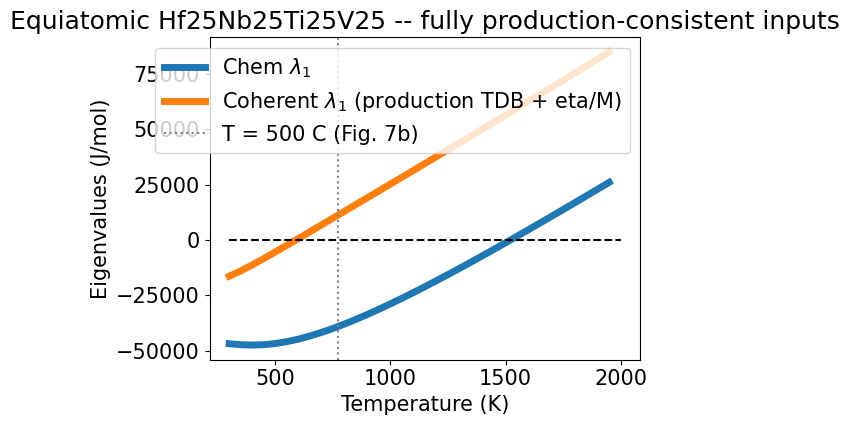

In [16]:
# Re-run the equiatomic (panel a) temperature sweep with production TDB *and* production eta/M/a
wks = Workspace(database=Database('/Users/vahid/Documents/GitHub/pycalphad-phase-field-coupling/data/tdb/HfNbTiV_BCC_PhaseForge_v2_Tdep.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.25,v.X('NB'): 0.25, v.X('TI'): 0.25, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))
dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))
dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF
d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB
d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta_arr = np.array([[eta_prod['HF'], eta_prod['NB'], eta_prod['TI']]])
M_pa = M_prod_GPa * 1e9
Vm_prod = (a_ref_prod*1e-10)**3 * 6.022e23 / 2
coherent_Hessian_const = 2*M_pa*Vm_prod*(eta_arr.reshape(-1,1) @ eta_arr)

chem_Hessian_list2, coherent_Hessian_list2 = [], []
for i in range(len(d2G_dxHFdxHF)):
    Hc = np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]],
                   [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]],
                   [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])
    chem_Hessian_list2.append(Hc)
    coherent_Hessian_list2.append(Hc + coherent_Hessian_const)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_eigenvalues_list2, coherent_eigenvalues_list2 = [], []
for i in range(len(d2G_dxHFdxHF)):
    chem_eigenvalues_list2.append(np.sort(np.linalg.eigvalsh(O.T@chem_Hessian_list2[i]@O)))
    coherent_eigenvalues_list2.append(np.sort(np.linalg.eigvalsh(O.T@coherent_Hessian_list2[i]@O)))

temps2 = np.arange(300,2000,50)
plt.figure(figsize=(6,4.5))
plt.plot(temps2, np.array(chem_eigenvalues_list2)[:,0], label='Chem $\\lambda_1$', linewidth=5)
plt.plot(temps2, np.array(coherent_eigenvalues_list2)[:,0], label='Coherent $\\lambda_1$ (production TDB + eta/M)', linewidth=5)
plt.axvline(773.15, color='gray', linestyle=':', label='T = 500 C (Fig. 7b)')
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
plt.title('Equiatomic Hf25Nb25Ti25V25 -- fully production-consistent inputs')
plt.tight_layout()
plt.savefig('/tmp/fig4_check/panel_a_fully_production_consistent.png', dpi=150, bbox_inches='tight')
plt.show()
